# Лабораторна 1. Основні бібліотеки. Лінійні моделі навчання.

В цій лабораторній роботі студенти:
- ознайомлюються з сервісом Colab;
- ознайомлюються з базовими бібліотеками для машинного навчання;
- тренують неглибокі лінійні моделі машинного навчання на базі простих регресій: лінійна, логістична, поліноміальна.

## 0. Налаштування середовища

### 0.0. Імпортуємо залежності

In [1]:
import sys
import os
import random
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt

### 0.1. Перевіряємо чи ми точно в Colab

In [2]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

assert IN_COLAB, f"Ця лаба має вокинуватися в Google Colab (https://colab.research.google.com/)"

Running in Colab: True


### 0.2. Фіксуємо всі джерела випадковості.
На GPU повна детермінованість трохи сповільнює тренування
(`cudnn.deterministic = True` вимикає частину швидких алгоритмів) —
тут це не критично, адже дані й модель дрібні.

In [3]:
SEED = 42

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

**Вправа 1.** Скористайся вбудованим модулем `random`. Спробуй `random.randint(1, 100)` і `random.shuffle()` на списку — випадковість буває не лише в числі, а й у перестановці. Згенеруй обома способами двічі ДО виклику `set_seed()` — переконайся, що результати різні. Потім ще двічі **ПІСЛЯ** з викликом set_seed() після кожної генерації і потім ще двічі **без проміжного виклику** `set_seed()`.

Після клітинки з кодом створи клітинку з маркдауном і поясни що відбувається після `set_seed()` і як це проявляється в результатах виконання коду.

In [4]:
numbers = list(range(10))  # список для shuffle


def draw():
    """Одне «генерування»: випадкове ціле + перемішана копія списку.
    Список копіюємо, бо random.shuffle міняє його НА МІСЦІ -- інакше
    кожен наступний виклик стартував би вже з іншого порядку елементів."""
    shuffled = numbers.copy()
    random.shuffle(shuffled)
    return random.randint(1, 100), shuffled


# 1) двічі ДО set_seed() -- стан генератора береться з ентропії ОС
before = [draw() for _ in range(2)]
print("ДО set_seed():")
for i, r in enumerate(before, 1):
    print(f"  спроба {i}: {r}")

set_seed()
print("\nSeed зафіксовано:", SEED)

# 2) двічі ПІСЛЯ set_seed() -- set_seed() перед КОЖНИМ окремим генеруванням
after = []
for _ in range(2):
    set_seed()
    after.append(draw())
print("ПІСЛЯ set_seed() (перед кожним генеруванням):")
for i, r in enumerate(after, 1):
    print(f"  спроба {i}: {r}")

# 3) ще двічі БЕЗ проміжних set_seed() -- генератор іде далі по своїй послідовності
no_reset = [draw() for _ in range(2)]
print("БЕЗ проміжних set_seed():")
for i, r in enumerate(no_reset, 1):
    print(f"  спроба {i}: {r}")

# перевірка: один set_seed() задає цілу ПОСЛІДОВНІСТЬ, і її можна відтворити
set_seed()
replay = [draw() for _ in range(3)]
print()
print("before[0] == before[1]        :", before[0] == before[1])
print("after[0] == after[1]          :", after[0] == after[1])
print("no_reset[0] == no_reset[1]    :", no_reset[0] == no_reset[1])
print("replay == after[0] + no_reset :", replay == [after[0], *no_reset])


ДО set_seed():
  спроба 1: (17, [0, 9, 8, 3, 4, 1, 6, 2, 7, 5])
  спроба 2: (37, [0, 3, 2, 4, 6, 9, 5, 1, 8, 7])

Seed зафіксовано: 42
ПІСЛЯ set_seed() (перед кожним генеруванням):
  спроба 1: (76, [7, 3, 2, 8, 5, 6, 9, 4, 0, 1])
  спроба 2: (76, [7, 3, 2, 8, 5, 6, 9, 4, 0, 1])
БЕЗ проміжних set_seed():
  спроба 1: (92, [4, 3, 2, 9, 5, 1, 7, 8, 0, 6])
  спроба 2: (44, [5, 1, 9, 0, 2, 4, 7, 3, 6, 8])

before[0] == before[1]        : False
after[0] == after[1]          : True
no_reset[0] == no_reset[1]    : False
replay == after[0] + no_reset : True


**Пояснення до вправи 1: що робить `set_seed()` і як це видно у виводі**

`random`, NumPy і PyTorch дають не справжні, а *псевдовипадкові* числа: це детермінований алгоритм (у Python — Mersenne Twister) із внутрішнім **станом**. Кожен виклик (`randint`, `shuffle`, ...) бере наступне число з цього стану й зсуває його далі. `set_seed(42)` записує в генератори (`random`, `numpy`, `torch`) відомий початковий стан, тобто фіксує початок послідовності.

Що видно у виводі:

1. **ДО `set_seed()`** — початковий стан береться з системної ентропії, тому дві спроби дають різні числа й різний порядок після `shuffle` (`before[0] == before[1]` → `False`). У свіжому ядрі кожен новий запуск дасть інші значення.
2. **ПІСЛЯ `set_seed()` перед кожним генеруванням** — обидві спроби збігаються повністю (`after[0] == after[1]` → `True`). Ми щоразу повертаємо генератор в один і той самий початковий стан, а з однакового стану виходять однакові «випадкові» числа. Через це результат однаковий і при повторному запуску комірки, і на чужому комп'ютері.
3. **БЕЗ проміжних `set_seed()`** — спроби знову різні (`no_reset[0] == no_reset[1]` → `False`): кожен виклик просунув стан вперед, і наступне генерування бере наступні числа послідовності. Це не хаос: після нового `set_seed()` три генерування підряд дають **точно ту саму** послідовність (`replay == after[0] + no_reset` → `True`). Seed фіксує не одне число, а всю послідовність.

**Практичний висновок.** `set_seed()` викликають **один раз на початку експерименту**, перед створенням даних, спліту й ініціалізацією ваг. Тоді весь експеримент відтворюваний, а числа всередині нього різні. Якщо викликати `set_seed()` перед кожною випадковою операцією, ми щоразу отримуватимемо одні й ті самі «випадкові» числа.

Окремо про `shuffle`: він змінює список на місці, тому у функції `draw()` ми перемішуємо **копію**. Без цього другий виклик стартував би вже з перемішаного списку, і результати розійшлись би навіть при однаковому seed.

### 0.3. Використовуємо лише CPU (в цій лабі)
На Colab зазвичай є безкоштовний GPU (T4), але для лінійної регресії
на кількасот точок CPU часто не повільніший — виграш GPU з'їдає пересилання
даних на пристрій і назад щоепохи. Тому нижче свідомо тренуємось на CPU.

In [5]:
device_available = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = torch.device("cpu")

print("Доступний пристрій :", device_available)
print("Використовуємо     :", device)
if device_available.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

assert device.type == "cpu", f"Ця лаба має виконуватися на CPU, а не на GPU ({device})"

Доступний пристрій : cpu
Використовуємо     : cpu


**Вправа 2.** Встанови CPU рантайм. Запусти комірку вище і зроби скріншот виводу. Потім у Colab зміни рантайм на GPU, перезапусти всі комірки від початку. Знову зроби скріншот тієї самої комірки. Збережи обидва скріншоти — пізніше завантажиш їх на GitHub разом зі здачею лаби.

### 0.4. Монтуємо Google Drive

Сесія Colab обмежена в часі й може скинутись — усе в `/content` зникає разом
з нею. Монтуємо Drive, щоб чекпоінт моделі й логи TensorBoard пережили
перезапуск.

In [6]:
from google.colab import drive
drive.mount("/content/drive")
ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab1"


os.makedirs(ARTIFACT_DIR, exist_ok=True)
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)
print("Артефакти зберігаються в:", ARTIFACT_DIR)


Mounted at /content/drive
Артефакти зберігаються в: /content/drive/MyDrive/ai_systems/lab1


---
## 1. Ознайомлення з бібліотеками

Кілька дуже простих вправ на NumPy, pandas, PyTorch і Matplotlib — щоб мати
спільну базу перед тим, як усі чотири підуть у хід одночасно.

### 1.1. NumPy

Документація: https://numpy.org/doc/stable/

**Вправа 3.** Створи масив форми 3×4, заповнений нулями (`np.zeros`), і ще один такої самої форми, заповнений числом 7 (`np.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [7]:
zeros_arr = np.zeros((3, 4))
sevens_arr = np.full((3, 4), 7)

print(zeros_arr, zeros_arr.shape, zeros_arr.dtype)
print(sevens_arr, sevens_arr.shape, sevens_arr.dtype)


[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]] (3, 4) float64
[[7 7 7 7]
 [7 7 7 7]
 [7 7 7 7]] (3, 4) int64


**Вправа 4.** Створи масив від 0 до 20 із кроком 2 через `np.arange`, і масив із 5 рівномірно розподілених точок від 0 до 1 через `np.linspace`. Виведи обидва.

In [8]:
arange_arr = np.arange(0, 20, 2)
linspace_arr = np.linspace(0, 1, 5)

print(arange_arr)
print(linspace_arr)


[ 0  2  4  6  8 10 12 14 16 18]
[0.   0.25 0.5  0.75 1.  ]


**Вправа 5.** Створи одиничну матрицю 4×4 (`np.eye`) і випадковий масив цілих чисел форми 3×3 у діапазоні [0, 10) (`np.random.randint`). Виведи `.ndim` обох масивів.

In [9]:
identity = np.eye(4)
random_ints = np.random.randint(0, 10, size=(3, 3))

print(identity)
print(random_ints)
print("ndim identity   :", identity.ndim)
print("ndim random_ints:", random_ints.ndim)


[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
[[6 3 7]
 [4 6 9]
 [2 6 7]]
ndim identity   : 2
ndim random_ints: 2


**Вправа 6.** Маєш масив оцінок студентів. Порахуй середнє, стандартне відхилення і z-normalized версію масиву — без циклів.

In [10]:
scores = np.array([78, 85, 92, 67, 90, 74, 88, 95, 60, 82])

mean = scores.mean()
std = scores.std()  # за замовчуванням ddof=0 (генеральне стандартне відхилення)
z_scores = (scores - mean) / std

print("Середнє:", mean, " Std:", std)
print("Z-scores:", z_scores)
print("mean(z) ≈ 0:", np.isclose(z_scores.mean(), 0), "| std(z) ≈ 1:", np.isclose(z_scores.std(), 1))


Середнє: 81.1  Std: 10.76522178127325
Z-scores: [-0.28796434  0.36227772  1.01251978 -1.30977329  0.82673633 -0.65953123
  0.64095289  1.29119495 -1.96001536  0.08360255]
mean(z) ≈ 0: True | std(z) ≈ 1: True


**Вправа 7.** Маєш 1D масив із 12 чисел. Перетвори його на матрицю 3×4 і порахуй суму кожного рядка та кожного стовпця.

In [11]:
arr = np.arange(1, 13)

matrix = arr.reshape(3, 4)
row_sums = matrix.sum(axis=1)  # по рядках: згортаємо стовпці
col_sums = matrix.sum(axis=0)  # по стовпцях: згортаємо рядки

print(matrix)
print("Сума по рядках:  ", row_sums)
print("Сума по стовпцях:", col_sums)


[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
Сума по рядках:   [10 26 42]
Сума по стовпцях: [15 18 21 24]


### 1.2. pandas

Документація: https://pandas.pydata.org/docs/

**Вправа 8.** Створи таблицю студентів з оцінками. Виведи тільки тих, хто набрав більше 80 балів, відсортованих за спаданням оцінки.

In [12]:
df = pd.DataFrame({
    "student": ["Олена", "Андрій", "Марія", "Богдан", "Софія",
                "Тарас", "Ірина", "Максим", "Дарина", "Олег"],
    "score": [78, 85, 92, 67, 90, 74, 88, 95, 60, 82],
})

top = df[df["score"] > 80].sort_values("score", ascending=False).reset_index(drop=True)
print(top)


  student  score
0  Максим     95
1   Марія     92
2   Софія     90
3   Ірина     88
4  Андрій     85
5    Олег     82


**Вправа 9.** Додай колонку `grade`: `A` якщо `score >= 90`, `B` якщо `score >= 75`, інакше `C`.

In [13]:
# score >= 90 -> "A", score >= 75 -> "B", інакше -> "C"
# np.select перевіряє умови по черзі й бере першу, що спрацювала
df["grade"] = np.select(
    [df["score"] >= 90, df["score"] >= 75],
    ["A", "B"],
    default="C",
)
print(df)


  student  score grade
0   Олена     78     B
1  Андрій     85     B
2   Марія     92     A
3  Богдан     67     C
4   Софія     90     A
5   Тарас     74     C
6   Ірина     88     B
7  Максим     95     A
8  Дарина     60     C
9    Олег     82     B


### 1.3. PyTorch

Документація: https://pytorch.org/docs/stable/index.html

**Вправа 10.** Створи тензор форми 2×3, заповнений нулями (`torch.zeros`), і ще один такої самої форми, заповнений числом 7 (`torch.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [14]:
zeros_t = torch.zeros((2, 3))
sevens_t = torch.full((2, 3), 7)

print(zeros_t, zeros_t.shape, zeros_t.dtype)
print(sevens_t, sevens_t.shape, sevens_t.dtype)


tensor([[0., 0., 0.],
        [0., 0., 0.]]) torch.Size([2, 3]) torch.float32
tensor([[7, 7, 7],
        [7, 7, 7]]) torch.Size([2, 3]) torch.int64


**Вправа 11.** Створи тензор від 0 до 20 із кроком 2 через `torch.arange`, і тензор із 5 рівномірно розподілених точок від 0 до 1 через `torch.linspace`.

In [15]:
arange_t = torch.arange(0, 20, 2)
linspace_t = torch.linspace(0, 1, 5)

print(arange_t)
print(linspace_t)


tensor([ 0,  2,  4,  6,  8, 10, 12, 14, 16, 18])
tensor([0.0000, 0.2500, 0.5000, 0.7500, 1.0000])


**Вправа 12.** Створи тензор напряму зі списку — `torch.tensor([[1, 2], [3, 4]])` — і випадковий тензор форми 3×3 через `torch.rand`. Виведи `.shape`, `.dtype` і `.ndim` обох.

In [16]:
from_list = torch.tensor([[1, 2], [3, 4]])
random_t = torch.rand(3, 3)

print(from_list)
print("shape:", from_list.shape, "| dtype:", from_list.dtype, "| ndim:", from_list.ndim)
print(random_t)
print("shape:", random_t.shape, "| dtype:", random_t.dtype, "| ndim:", random_t.ndim)


tensor([[1, 2],
        [3, 4]])
shape: torch.Size([2, 2]) | dtype: torch.int64 | ndim: 2
tensor([[0.8823, 0.9150, 0.3829],
        [0.9593, 0.3904, 0.6009],
        [0.2566, 0.7936, 0.9408]])
shape: torch.Size([3, 3]) | dtype: torch.float32 | ndim: 2


**Вправа 13.** Створи тензор `x = 5.0` з `requires_grad=True`, порахуй `y = x**2` і перевір автоматичний градієнт проти аналітичного ($dy/dx = 2x$).

In [17]:
n = 5.0

x = torch.tensor(n, requires_grad=True)
y = x ** 2
y.backward()  # autograd порахує dy/dx і запише в x.grad

analytic = 2 * n  # dy/dx = 2x
print(f"autograd: {x.grad.item()}  |  аналітично 2x: {analytic}")
assert abs(x.grad.item() - analytic) < 1e-6, "градієнти не збіглися!"


autograd: 10.0  |  аналітично 2x: 10.0


**Вправа 14.** Знайди $x$, який мінімізує $(x-3)^2 + 5$ — не аналітично, а градієнтним спуском: `x` як параметр з `requires_grad=True`, без жодної моделі.

In [18]:
x = torch.tensor(0.0, requires_grad=True)
lr = 0.1

for step in range(20):
    loss = (x - 3) ** 2 + 5
    loss.backward()
    with torch.no_grad():
        x -= lr * x.grad
    x.grad.zero_()

print(f"x = {x.item():.4f}  (мінімум у x=3)")
print(f"loss = {((x - 3) ** 2 + 5).item():.4f}  (мінімум дорівнює 5)")
# Кожен крок множить відстань до мінімуму на (1 - 2*lr) = 0.8, тож після 20 кроків
# лишається 3 * 0.8**20 ≈ 0.035: x близький до 3, але ще не дорівнює йому.


x = 2.9654  (мінімум у x=3)
loss = 5.0012  (мінімум дорівнює 5)


### 1.4. Matplotlib

Документація: https://matplotlib.org/stable/index.html

**Вправа 15.** Побудуй графік функції $y = \sin(x)$ на проміжку $[0, 2\pi]$.

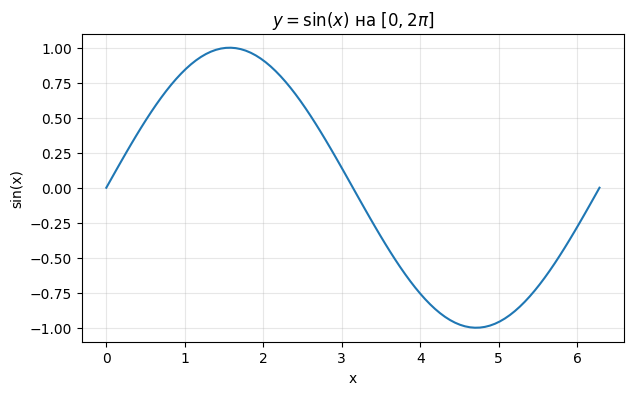

In [19]:
xs = np.linspace(0, 2 * np.pi, 100)

plt.figure(figsize=(7, 4))
plt.plot(xs, np.sin(xs))
plt.xlabel("x")
plt.ylabel("sin(x)")
plt.title(r"$y = \sin(x)$ на $[0, 2\pi]$")
plt.grid(alpha=0.3)
plt.show()


**Вправа 16.** На одному графіку познач дві групи точок різними кольорами і додай легенду.

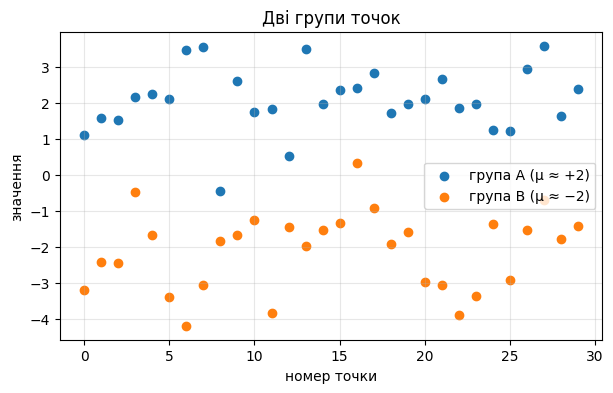

In [20]:
group_a = np.random.randn(30) + 2
group_b = np.random.randn(30) - 2

idx = np.arange(30)
plt.figure(figsize=(7, 4))
plt.scatter(idx, group_a, color="C0", label="група A (μ ≈ +2)")
plt.scatter(idx, group_b, color="C1", label="група B (μ ≈ −2)")
plt.xlabel("номер точки")
plt.ylabel("значення")
plt.title("Дві групи точок")
plt.grid(alpha=0.3)
plt.legend()
plt.show()


---
## Завдання 1. Лінійна регресія

Тренуємо базовий пайплайн на простій лінійній регресії з одним параметром.

$$y = w \cdot x + b + \varepsilon, \quad \varepsilon \sim \mathcal{N}(0, 1)$$

In [21]:
set_seed()  # дані й подальший спліт стають відтворюваними незалежно від попередніх комірок

TASK1_TRUE_W = 2.0
TASK1_TRUE_B = 1.0
TASK1_N = 300

x1 = torch.empty(TASK1_N, 1).uniform_(-5, 5)
noise = 1.0 * torch.randn(TASK1_N, 1)
y1 = TASK1_TRUE_W * x1 + TASK1_TRUE_B + noise

**Вправа 17.** Перш ніж будувати модель — подивись на самі дані.

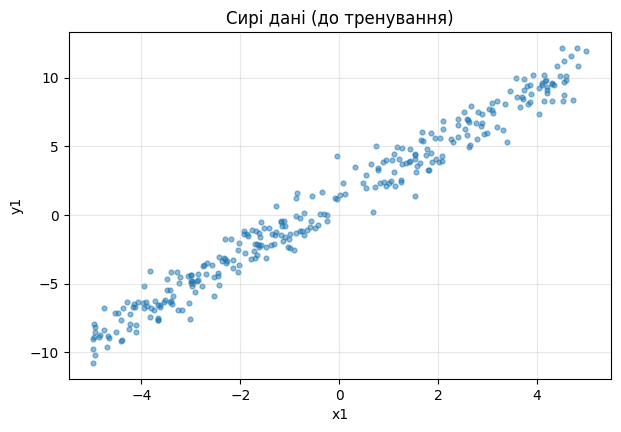

In [22]:
plt.figure(figsize=(7, 4.5))
plt.scatter(x1.numpy(), y1.numpy(), s=12, alpha=0.5)
plt.xlabel("x1")
plt.ylabel("y1")
plt.title("Сирі дані (до тренування)")
plt.grid(alpha=0.3)
plt.show()


**Вправа 18.** Розбий дані на train/val/test (70/15/15). Перемішай дані перед зрізом, інакше спліт вийде не випадковим.

In [23]:
perm = torch.randperm(TASK1_N)  # випадкова перестановка індексів
x_shuf, y_shuf = x1[perm], y1[perm]

n_train = round(0.70 * TASK1_N)  # 210
n_val = round(0.15 * TASK1_N)    # 45
# решта (45) іде в test, тож жодна точка не втрачається і не дублюється

x_train1, y_train1 = x_shuf[:n_train], y_shuf[:n_train]
x_val1, y_val1 = x_shuf[n_train:n_train + n_val], y_shuf[n_train:n_train + n_val]
x_test1, y_test1 = x_shuf[n_train + n_val:], y_shuf[n_train + n_val:]

print(f"train/val/test: {len(x_train1)}/{len(x_val1)}/{len(x_test1)}")


train/val/test: 210/45/45


**Вправа 19.** Нижче — готовий цикл навчання, кожен крок підписаний окремо. Просто запусти обидві комірки й подивись, як модель наближається до `true` за 100 епох (знімки кожні 30 епох).

In [24]:
task1_model = torch.nn.Linear(in_features=1, out_features=1)
optimizer = torch.optim.SGD(task1_model.parameters(), lr=0.05)
loss_fn = torch.nn.MSELoss()

x_line = torch.linspace(-5, 5, 100).unsqueeze(1)  # сітка для візуалізації лінії
snapshots = []  # (epoch, w, b, y_line_pred) кожні 30 епох

for epoch in range(100):
    # обнулити градієнти з попереднього кроку
    optimizer.zero_grad()
    # forward -- прогноз моделі на поточних w, b
    y_pred = task1_model(x_train1)
    # loss -- наскільки прогноз відрізняється від y_train1
    loss = loss_fn(y_pred, y_train1)
    # backward -- градієнти loss за w і b
    loss.backward()
    # крок оптимізатора -- оновити w і b
    optimizer.step()

    if epoch % 30 == 0 or epoch == 99:
        with torch.no_grad():
            y_line_pred = task1_model(x_line)
        snapshots.append((epoch, task1_model.weight.item(), task1_model.bias.item(), y_line_pred))
        print(f"epoch {epoch:4d}  loss={loss.item():.6f}  "
              f"w={task1_model.weight.item():.4f} (true {TASK1_TRUE_W})  "
              f"b={task1_model.bias.item():.4f} (true {TASK1_TRUE_B})")


epoch    0  loss=52.999176  w=1.7073 (true 2.0)  b=-0.1046 (true 1.0)
epoch   30  loss=0.873840  w=2.0204 (true 2.0)  b=0.9961 (true 1.0)
epoch   60  loss=0.870761  w=2.0217 (true 2.0)  b=1.0441 (true 1.0)
epoch   90  loss=0.870755  w=2.0218 (true 2.0)  b=1.0462 (true 1.0)
epoch   99  loss=0.870755  w=2.0218 (true 2.0)  b=1.0462 (true 1.0)


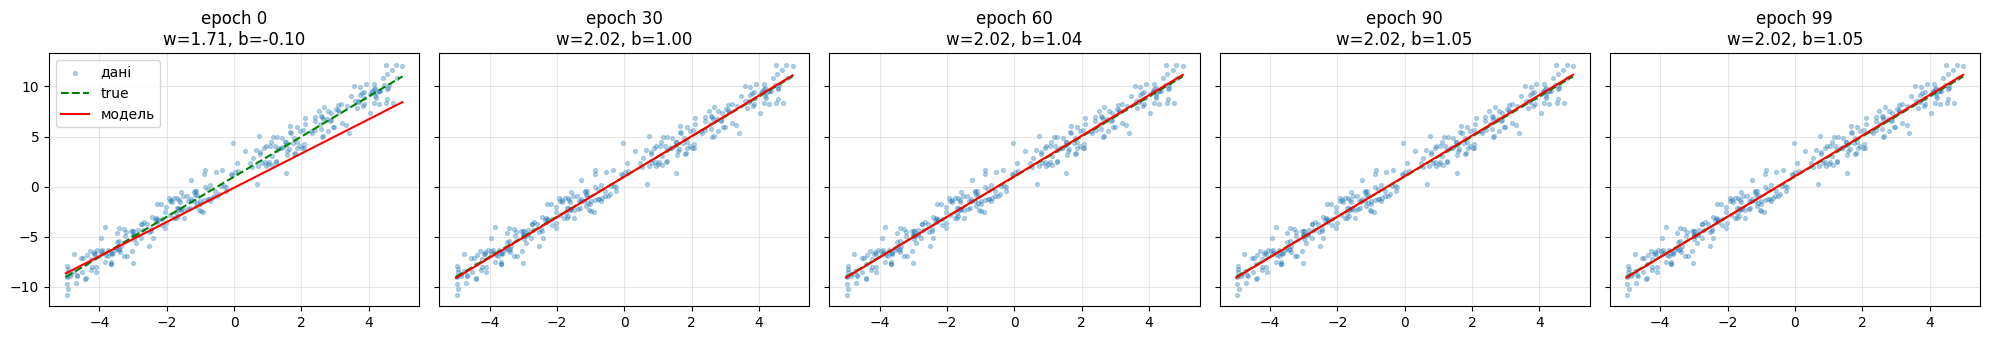

In [25]:
with torch.no_grad():
    y_line_true = TASK1_TRUE_W * x_line + TASK1_TRUE_B

fig, axes = plt.subplots(1, len(snapshots), figsize=(4 * len(snapshots), 3.5), sharey=True)
for ax, (epoch, w, b, y_line_pred) in zip(axes, snapshots):
    ax.scatter(x1.numpy(), y1.numpy(), s=8, alpha=0.3, label="дані")
    ax.plot(x_line.numpy(), y_line_true.numpy(), "g--", label="true")
    ax.plot(x_line.numpy(), y_line_pred.numpy(), "r-", label="модель")
    ax.set_title(f"epoch {epoch}\nw={w:.2f}, b={b:.2f}")
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()


In [26]:
# Перевірка на val/test -- даних, яких модель під час тренування не бачила
with torch.no_grad():
    val_mse = loss_fn(task1_model(x_val1), y_val1).item()
    test_mse = loss_fn(task1_model(x_test1), y_test1).item()

print(f"MSE: train (остання епоха) = {loss.item():.4f} | val = {val_mse:.4f} | test = {test_mse:.4f}")
print("Шум має σ = 1, тож нижня межа MSE ≈ σ² = 1.0: точніше за сам шум модель бути не може.")


MSE: train (остання епоха) = 0.8708 | val = 1.1105 | test = 1.1889
Шум має σ = 1, тож нижня межа MSE ≈ σ² = 1.0: точніше за сам шум модель бути не може.


**Вправа 20.** Придумай власний напів-реальний сценарій лінійної залежності
(наприклад: кількість з'їдених пачок чіпсів на тиждень → індекс маси тіла;
години сну → продуктивність; щось своє). У markdown-комірці перед кодом
опиши сценарій: яку залежність ти
закладаєш ($w$, $b$) і чому саме такі значення видались тобі правдоподібними.
Згенеруй дані з шумом, збережи їх у CSV файл (за зразком відповідної частини лекції)
і натренуй лінійну регресію за тим самим патерном — спліт, цикл навчання, перевірка на test.
Організуй код тренування у логічні перевикористовувані функції.

### Вправа 20. Власний сценарій: години підготовки → бал за контрольну

**Ситуація.** Студент ФІКТ щотижня самостійно готується до контрольної (розв'язує задачі, перечитує конспекти). Нехай $x$ — кількість годин такої підготовки на тиждень (від 0 до 12), а $y$ — бал за контрольну за 100-бальною шкалою.

**Закладена залежність:**

$$y = 4.0 \cdot x + 35 + \varepsilon, \qquad \varepsilon \sim \mathcal{N}(0,\ 5^2)$$

**Чому саме такі значення:**

- $w = 4.0$ **бали за годину.** Година продуктивної підготовки додає в середньому кілька балів. Десять годин на тиждень дають приблизно +40 балів. Це відповідає різниці між «ледь склав» і «добре», і для роботи з однією залежною змінною такий нахил правдоподібний.
- $b = 35$ **балів без підготовки.** Нульова підготовка не означає нуль балів: частину матеріалу засвоюють на парах, частину тестових питань вгадують. З іншого боку, 35 лишається нижче прохідного бала.
- $\sigma = 5$ **балів шуму.** Бал залежить і від того, чого модель не знає: самопочуття в день контрольної, складності варіанта, везіння з питаннями, якості годин (година із задачами не дорівнює годині з телефоном). Тому дві людини з однаковою підготовкою отримують різні бали, а типовий розкид — кілька балів.
- $x \in [0, 12]$ **годин.** При $x = 12$ очікуваний бал ≈ 83, тож навіть із шумом $3\sigma$ значення не виходять за межі шкали 0–100 і обрізати (clip) їх не потрібно.

Далі: генеруємо $N = 400$ точок, зберігаємо їх у `dataset.csv`, читаємо назад **з файлу** й проходимо весь пайплайн: спліт 70/15/15 → нормалізація за статистиками train → тренування `nn.Linear(1, 1)` градієнтним спуском → оцінка на test. Код організовано в окремі функції, які можна використати повторно.

In [27]:
# --- Параметри сценарію ------------------------------------------------------
SCEN_TRUE_W = 4.0        # +4 бали за кожну додаткову годину підготовки
SCEN_TRUE_B = 35.0       # бал за нульової підготовки
SCEN_NOISE_STD = 5.0     # σ шуму (бали)
SCEN_N = 400
SCEN_MAX_HOURS = 12.0
FEATURE_COL, TARGET_COL = "study_hours", "exam_score"
DATASET_PATH = os.path.join(ARTIFACT_DIR, "dataset.csv")


def generate_dataset(n, true_w, true_b, noise_std, max_x, seed=SEED):
    """y = w*x + b + N(0, σ²), x ~ U(0, max_x).
    Окремий генератор з seed: таблиця щоразу однакова і не залежить від глобального стану."""
    rng = np.random.default_rng(seed)
    x = rng.uniform(0, max_x, size=n)
    y = true_w * x + true_b + rng.normal(0, noise_std, size=n)
    return pd.DataFrame({FEATURE_COL: x.round(2), TARGET_COL: y.round(1)})


def save_dataset(df, path):
    df.to_csv(path, index=False)
    print(f"Збережено {len(df)} рядків у {path}")


scen_df = generate_dataset(SCEN_N, SCEN_TRUE_W, SCEN_TRUE_B, SCEN_NOISE_STD, SCEN_MAX_HOURS)
save_dataset(scen_df, DATASET_PATH)
print(scen_df.head())
scen_df.describe().round(2)


Збережено 400 рядків у /content/drive/MyDrive/ai_systems/lab1/dataset.csv
   study_hours  exam_score
0         9.29        74.3
1         5.27        58.7
2        10.30        77.6
3         8.37        61.4
4         1.13        28.0


,study_hours,exam_score
count,400.00,400.00
mean,5.96,58.58
std,3.42,14.94
min,0.09,28.00
25%,2.88,46.10
50%,5.90,58.80
75%,9.10,70.12
max,11.91,89.40


In [28]:
def load_dataset(path):
    """CSV -> (DataFrame, x, y); x та y -- float32-тензори форми (N, 1)."""
    df = pd.read_csv(path)
    x = torch.tensor(df[[FEATURE_COL]].values, dtype=torch.float32)
    y = torch.tensor(df[[TARGET_COL]].values, dtype=torch.float32)
    return df, x, y


def split_data(x, y, train_frac=0.70, val_frac=0.15, seed=SEED):
    """Перемішує дані й ріже на train/val/test. Власний Generator робить спліт відтворюваним."""
    n = len(x)
    g = torch.Generator().manual_seed(seed)
    perm = torch.randperm(n, generator=g)
    n_train = round(train_frac * n)
    n_val = round(val_frac * n)
    idx = {
        "train": perm[:n_train],
        "val": perm[n_train:n_train + n_val],
        "test": perm[n_train + n_val:],
    }
    return {name: (x[i], y[i]) for name, i in idx.items()}


class Standardizer:
    """z-нормалізація (t - mean) / std.
    Статистики рахуємо ТІЛЬКИ на train, щоб інформація з val/test не просочилась у тренування."""

    def fit(self, t):
        self.mean = t.mean(dim=0, keepdim=True)
        self.std = t.std(dim=0, keepdim=True)
        return self

    def transform(self, t):
        return (t - self.mean) / self.std

    def inverse_transform(self, t):
        return t * self.std + self.mean


In [29]:
def train_linear_regression(x_train, y_train, x_val, y_val, epochs=200, lr=0.05):
    """Повнобатчевий градієнтний спуск для Linear(1, 1) з MSE-втратою.
    Повертає натреновану модель та історію train/val втрат по епохах."""
    model = torch.nn.Linear(in_features=1, out_features=1)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    loss_fn = torch.nn.MSELoss()
    history = {"train": [], "val": []}

    for epoch in range(epochs):
        optimizer.zero_grad()                       # 1. обнулити старі градієнти
        loss = loss_fn(model(x_train), y_train)     # 2. forward + loss
        loss.backward()                             # 3. backward: градієнти за w, b
        optimizer.step()                            # 4. крок оптимізатора

        with torch.no_grad():
            val_loss = loss_fn(model(x_val), y_val).item()
        history["train"].append(loss.item())
        history["val"].append(val_loss)
    return model, history


@torch.no_grad()
def predict(model, x, x_scaler, y_scaler):
    """x у реальних одиницях -> прогноз у реальних одиницях (балах)."""
    return y_scaler.inverse_transform(model(x_scaler.transform(x)))


def regression_metrics(y_true, y_pred):
    err = y_pred - y_true
    mse = err.pow(2).mean().item()
    ss_res = err.pow(2).sum()
    ss_tot = (y_true - y_true.mean()).pow(2).sum()
    return {
        "MSE": mse,
        "RMSE": mse ** 0.5,
        "MAE": err.abs().mean().item(),
        "R2": (1 - ss_res / ss_tot).item(),
    }


def print_metrics(name, y_true, y_pred):
    m = regression_metrics(y_true, y_pred)
    print(f"{name:>5}: MSE={m['MSE']:7.3f}  RMSE={m['RMSE']:6.3f}  MAE={m['MAE']:6.3f}  R²={m['R2']:.4f}")


def original_scale_params(model, x_scaler, y_scaler):
    """Переводить (w, b) моделі, навченої на нормалізованих даних, у реальні одиниці:
    y = σy * (w_s * (x - μx) / σx + b_s) + μy."""
    w_s, b_s = model.weight.item(), model.bias.item()
    x_mean, x_std = x_scaler.mean.item(), x_scaler.std.item()
    y_mean, y_std = y_scaler.mean.item(), y_scaler.std.item()
    w = w_s * y_std / x_std
    b = y_mean + y_std * (b_s - w_s * x_mean / x_std)
    return w, b


def plot_results(history, x_train, y_train, x_test, y_test, w, b, true_w, true_b, x_max):
    fig, (ax_loss, ax_fit) = plt.subplots(1, 2, figsize=(12, 4.2))

    ax_loss.plot(history["train"], label="train")
    ax_loss.plot(history["val"], label="val")
    ax_loss.set_xlabel("епоха")
    ax_loss.set_ylabel("MSE (на нормалізованих даних)")
    ax_loss.set_title("Криві навчання")
    ax_loss.grid(alpha=0.3)
    ax_loss.legend()

    xs = np.linspace(0, x_max, 50)
    ax_fit.scatter(x_train.numpy(), y_train.numpy(), s=10, alpha=0.3, label="train")
    ax_fit.scatter(x_test.numpy(), y_test.numpy(), s=22, color="C1", label="test")
    ax_fit.plot(xs, true_w * xs + true_b, "g--", label=f"істинна: y = {true_w:.1f}·x + {true_b:.1f}")
    ax_fit.plot(xs, w * xs + b, "r-", label=f"модель: y = {w:.2f}·x + {b:.2f}")
    ax_fit.set_xlabel("години підготовки на тиждень")
    ax_fit.set_ylabel("бал за контрольну")
    ax_fit.set_title("Лінія регресії на тлі даних")
    ax_fit.grid(alpha=0.3)
    ax_fit.legend()

    plt.tight_layout()
    plt.show()


In [30]:
set_seed()  # для ініціалізації ваг nn.Linear

# 1. дані читаємо саме з CSV, який щойно зберегли
scen_loaded, x2, y2 = load_dataset(DATASET_PATH)

# 2. спліт 70/15/15
splits = split_data(x2, y2)
x_tr, y_tr = splits["train"]
x_va, y_va = splits["val"]
x_te, y_te = splits["test"]
print(f"train/val/test: {len(x_tr)}/{len(x_va)}/{len(x_te)}")

# 3. нормалізація: статистики лише з train
x_scaler = Standardizer().fit(x_tr)
y_scaler = Standardizer().fit(y_tr)

# 4. тренування
scen_model, scen_history = train_linear_regression(
    x_scaler.transform(x_tr), y_scaler.transform(y_tr),
    x_scaler.transform(x_va), y_scaler.transform(y_va),
    epochs=200, lr=0.05,
)
print(f"loss train: {scen_history['train'][0]:.4f} -> {scen_history['train'][-1]:.4f} | "
      f"val: {scen_history['val'][0]:.4f} -> {scen_history['val'][-1]:.4f}")

# 5. оцінка в реальних одиницях (бали); test -- це фінальна перевірка
print("\nМетрики:")
for name, (x_part, y_part) in [("train", (x_tr, y_tr)), ("val", (x_va, y_va)), ("test", (x_te, y_te))]:
    print_metrics(name, y_part, predict(scen_model, x_part, x_scaler, y_scaler))

# Теоретична межа R²: частка дисперсії, яку пояснює сигнал w*x, на тлі нестисного шуму σ²
signal_var = SCEN_TRUE_W ** 2 * SCEN_MAX_HOURS ** 2 / 12  # Var(w*x) для x ~ U(0, max)
r2_ceiling = signal_var / (signal_var + SCEN_NOISE_STD ** 2)
print(f"Теоретична межа R² при ідеально відомих w, b: {r2_ceiling:.4f}")

# 6. параметри в реальних одиницях: істинні vs навчені vs аналітичний МНК
w_hat, b_hat = original_scale_params(scen_model, x_scaler, y_scaler)
w_ols, b_ols = np.polyfit(x_tr.squeeze(1).numpy(), y_tr.squeeze(1).numpy(), deg=1)
print(f"\n{'':>14}{'w':>9}{'b':>9}")
print(f"{'істинні':>14}{SCEN_TRUE_W:9.3f}{SCEN_TRUE_B:9.3f}")
print(f"{'градієнт. спуск':>14}{w_hat:9.3f}{b_hat:9.3f}")
print(f"{'МНК (polyfit)':>14}{w_ols:9.3f}{b_ols:9.3f}")
print("Градієнтний спуск збігся з МНК:", bool(np.allclose([w_hat, b_hat], [w_ols, b_ols], atol=1e-2)))


train/val/test: 280/60/60
loss train: 0.8356 -> 0.1160 | val: 0.8313 -> 0.1134

Метрики:
train: MSE= 24.356  RMSE= 4.935  MAE= 3.909  R²=0.8836
  val: MSE= 23.796  RMSE= 4.878  MAE= 4.000  R²=0.9126
 test: MSE= 33.286  RMSE= 5.769  MAE= 4.848  R²=0.8410
Теоретична межа R² при ідеально відомих w, b: 0.8848

                      w        b
       істинні    4.000   35.000
градієнт. спуск    4.111   34.099
 МНК (polyfit)    4.111   34.099
Градієнтний спуск збігся з МНК: True


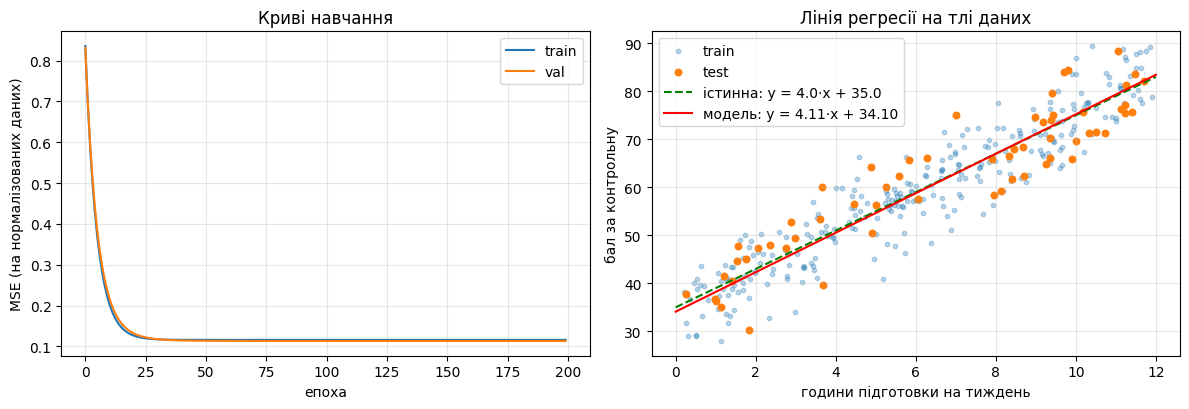

In [31]:
plot_results(
    scen_history, x_tr, y_tr, x_te, y_te,
    w=w_hat, b=b_hat, true_w=SCEN_TRUE_W, true_b=SCEN_TRUE_B, x_max=SCEN_MAX_HOURS,
)


**Вправа 21.** Збережи натреновану модель на своєму гугл диску у файлі з назвою `model.pt`.
Збережений файл потрібно буде також здати разом з лабою.

In [32]:
MODEL_PATH = os.path.join(ARTIFACT_DIR, "model.pt")


def save_checkpoint(path, model, x_scaler, y_scaler):
    """Зберігаємо не лише ваги, а й статистики нормалізації: без них прогноз у балах неможливий.
    Усе в чистих тензорах/числах/рядках, тому файл безпечно читати з weights_only=True."""
    torch.save({
        "state_dict": model.state_dict(),
        "x_mean": x_scaler.mean.item(), "x_std": x_scaler.std.item(),
        "y_mean": y_scaler.mean.item(), "y_std": y_scaler.std.item(),
        "feature": FEATURE_COL, "target": TARGET_COL, "max_hours": SCEN_MAX_HOURS,
    }, path)


def load_checkpoint(path):
    ckpt = torch.load(path, map_location="cpu", weights_only=True)
    model = torch.nn.Linear(in_features=1, out_features=1)
    model.load_state_dict(ckpt["state_dict"])
    model.eval()
    return model, ckpt


@torch.no_grad()
def predict_score(model, ckpt, hours):
    """hours (число, масив або тензор) -> прогноз балу, тензор форми (N, 1)."""
    x = torch.as_tensor(hours, dtype=torch.float32).reshape(-1, 1)
    z = (x - ckpt["x_mean"]) / ckpt["x_std"]
    return model(z) * ckpt["y_std"] + ckpt["y_mean"]


save_checkpoint(MODEL_PATH, scen_model, x_scaler, y_scaler)
print(f"Модель збережено: {MODEL_PATH} ({os.path.getsize(MODEL_PATH)} байт)")

# перевірка: модель, завантажена з диска, дає ті самі прогнози, що й та, що в пам'яті
loaded_model, loaded_ckpt = load_checkpoint(MODEL_PATH)
same = torch.allclose(
    predict_score(loaded_model, loaded_ckpt, x_te),
    predict(scen_model, x_te, x_scaler, y_scaler),
    atol=1e-3,
)
print("Прогнози після перезавантаження збігаються:", same)
print("Приклад: 8 годин на тиждень ->", round(predict_score(loaded_model, loaded_ckpt, 8.0).item(), 1), "балів")


Модель збережено: /content/drive/MyDrive/ai_systems/lab1/model.pt (2069 байт)
Прогнози після перезавантаження збігаються: True
Приклад: 8 годин на тиждень -> 67.0 балів


**Вправа 22.** Встанови [Gradio](https://gradio.app/)
```
!pip install -q gradio
import gradio as gr
```
Завантаж свою модель, збережену в попередній вправі і створи інтерактивну аппку.

In [33]:
!pip install -q gradio
import gradio as gr


In [34]:
from matplotlib.figure import Figure

# завантажуємо модель з диска -- саме той model.pt, що зберегли у вправі 21
app_model, app_ckpt = load_checkpoint(MODEL_PATH)
app_data = pd.read_csv(DATASET_PATH)


def predict_ui(hours):
    score = predict_score(app_model, app_ckpt, hours).item()

    fig = Figure(figsize=(5.5, 3.8))  # Figure без pyplot: не накопичує відкритих фігур між запитами
    ax = fig.subplots()
    ax.scatter(app_data[FEATURE_COL], app_data[TARGET_COL], s=10, alpha=0.3, label="дані")
    xs = np.linspace(0, app_ckpt["max_hours"], 50)
    ax.plot(xs, predict_score(app_model, app_ckpt, xs).squeeze(1).numpy(), "r-", label="модель")
    ax.scatter([hours], [score], color="black", s=70, zorder=5, label="ваш прогноз")
    ax.set_xlabel("години підготовки на тиждень")
    ax.set_ylabel("бал за контрольну")
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    return round(score, 1), fig


demo = gr.Interface(
    fn=predict_ui,
    inputs=gr.Slider(minimum=0, maximum=app_ckpt["max_hours"], value=6, step=0.5,
                     label="Годин самостійної підготовки на тиждень"),
    outputs=[gr.Number(label="Прогноз балу за контрольну (0–100)"),
             gr.Plot(label="Модель на тлі даних")],
    title="Скільки годин підготовки — такий і бал",
    description="Лінійна регресія (PyTorch), навчена на синтетичних даних: "
                "y = 4·x + 35 + шум. Пересуньте повзунок, щоб побачити прогноз.",
)
demo.launch()


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://be363344b479ba7b8a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
## Висновки

- Освоєно базові бібліотеки: **NumPy** (масиви, векторизація без циклів), **pandas** (фільтрація, сортування, нові колонки), **PyTorch** (тензори, autograd, градієнтний спуск «вручну») та **Matplotlib** (лінійні й точкові графіки з легендою).
- Відтворюваність забезпечує одноразовий `set_seed()` на початку експерименту (вправа 1): однаковий seed дає однакову послідовність «випадкових» чисел, а отже однакові дані, спліт і початкові ваги.
- Лінійну регресію реалізовано як `nn.Linear(1, 1)` + MSE + SGD. Один крок навчання складається з `zero_grad → forward → backward → step`.
- У власному сценарії дані розбито на train/val/test (70/15/15) з перемішуванням. Нормалізацію навчено лише на train, щоб уникнути витоку інформації. Фінальну якість оцінено на test за MSE, RMSE, MAE та R².
- Навчені параметри переведено в реальні одиниці й порівняно з істинними та з аналітичним МНК. Точніше за шум σ модель бути не може: теоретична межа R² визначається співвідношенням сигналу й шуму в даних.
- Модель збережено в `model.pt` (ваги й статистики нормалізації) та підключено до інтерактивного застосунку Gradio.

---
### Як здавати лабу
У [форму](https://forms.gle/5qxRYshxKknBXDCz8) здати посилання на **публічний** репозиторій, який містить:
1. **Цей ноутбук з усіма виконаними вправами**. Ноутбук має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Додаткові скріншоти** по ходу виконання лаби (якими Ви доводите, що справді виконували цбю лабу).
3. Створений по ходу виконання лаби **csv файл** з даними і **pt файл** з моделлю.
4. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
    /lab1/linear_models_lab.ipynb
    /lab1/screenshots/*
    /lab1/dataset.csv
    /lab1/model.pt
```